**Checking Tile Features from Auburn**

In [1]:
import pandas as pd 

df_auburn_tile_features = pd.read_parquet(r"C:\Users\u355394\OneDrive - IBERDROLA S.A\Documents - Asset Data Strategy\Asset Data Quality\SmartLink\data\cache\tile_features\current\Auburn.parquet")

**Today's date**

In [2]:
from datetime import datetime
today = datetime.today().strftime('%Y-%m-%d')

In [3]:
df_auburn_features = pd.read_parquet(fr"C:\Users\u355394\OneDrive - IBERDROLA S.A\Documents - Asset Data Strategy\Asset Data Quality\SmartLink\data\cache\candidate_features\{today}\Auburn.parquet")

In [4]:
auburn_meter_trasnformer_candidates = df_auburn_features[['meter_number','candidate_transformer',  'transformer_latitude', 'transformer_longitude', 'meter_latitude', 'meter_longitude']]

**Let's look at an example and check if the maps reflects that**

In [5]:
def create_google_maps_link(
    start_lat,
    start_lon,
    end_lat,
    end_lon,
):
    return (
        f"https://www.google.com/maps/dir/"
        f"{float(start_lat):.6f},{float(start_lon):.6f}/"
        f"{float(end_lat):.6f},{float(end_lon):.6f}"
    )

**Google map link for every candidate**

In [6]:
tile_check = (
    df_auburn_tile_features
    .merge(
        auburn_meter_trasnformer_candidates,
        on=["meter_number", "candidate_transformer"],
        how="left"
    )
)


tile_check["google_maps_link"] = tile_check.apply(
    lambda r: create_google_maps_link(
        r["meter_latitude"],
        r["meter_longitude"],
        r["transformer_latitude"],
        r["transformer_longitude"],
    ),
    axis=1,
)

**Manual Check between NSL0300225375 and 9301-L0792-0001-0012-ED00010: I looked at google maps and it does show that there are 3 building / houses in between**

In [7]:
sample_test = df_auburn_tile_features[(df_auburn_tile_features['meter_number'] == 'NSL0300225375') & (df_auburn_tile_features['candidate_transformer'] == '9301-L0792-0001-0012-ED00010')]

## Looking at google maps just to be sure
meter_sample =   auburn_meter_trasnformer_candidates[auburn_meter_trasnformer_candidates['meter_number'] == 'NSL0300225375'].reset_index(drop=True)
create_google_maps_link(start_lat=42.929765, start_lon=-76.574811	,end_lat=42.930623, end_lon=-76.575874)

'https://www.google.com/maps/dir/42.929765,-76.574811/42.930623,-76.575874'

**Manual Review of NSL0300547825 and  9301-L0775-0001-0023-ED00022:**


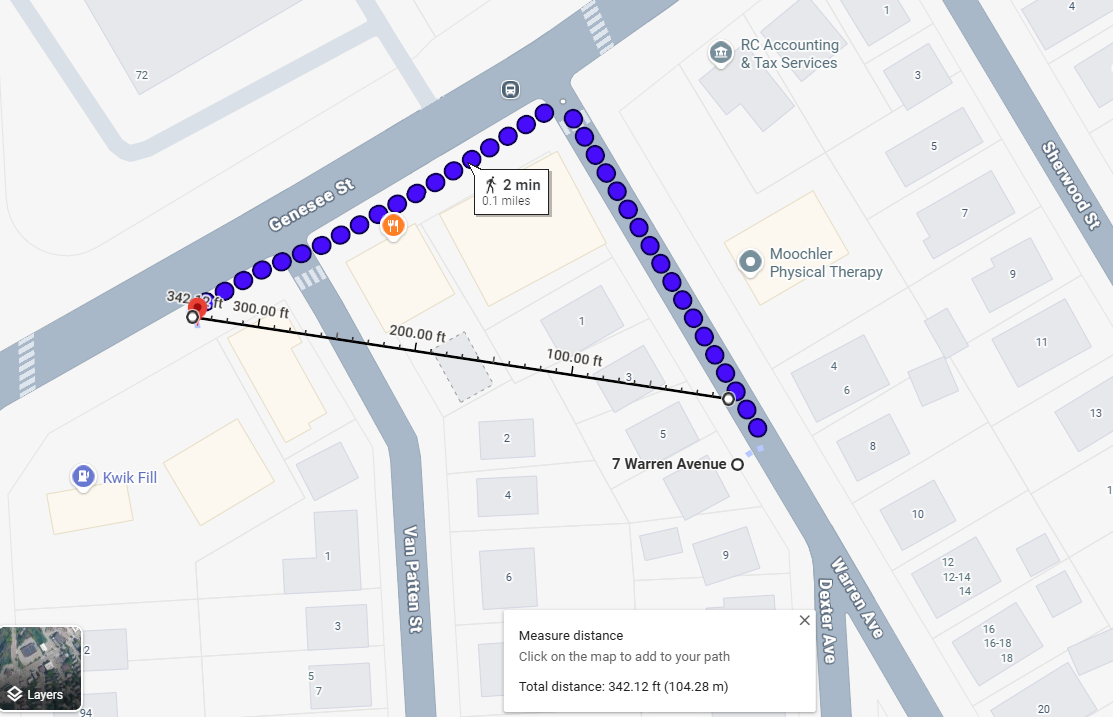

In [42]:
tile_check[(tile_check['meter_number'] == 'NSL0300547825') & (tile_check['candidate_transformer'] == '9301-L0775-0001-0023-ED00022')]

,meter_number,candidate_transformer,division,straight_line_length_ft,building_count_between,blocked_length_ft,building_between_flag,pct_line_blocked_by_building,street_crossing_count,street_crossing_flag,...,barrier_crossing_count,barrier_crossing_flag,landuse_crossing_count,landuse_crossing_flag,spatial_obstruction_score,transformer_latitude,transformer_longitude,meter_latitude,meter_longitude,google_maps_link
26004,NSL0300547825,9301-L0775-0001-0023-ED00022,Auburn,352.12796,3,81.332092,1,0.230973,1,1,...,0,0,0,0,10.19292,42.92251,-76.58397,42.922274,-76.582694,"https://www.google.com/maps/dir/42.922274,-76...."


**CORRECTTTT Tile Features passed the test**

**Do tile Features and Candidate and Candidate Feature files have discrepancies??**

In [8]:
candidate_meters_auburn = pd.read_parquet(fr"C:\Users\u355394\OneDrive - IBERDROLA S.A\Documents - Asset Data Strategy\Asset Data Quality\SmartLink\data\cache\candidates\{today}\meters\Auburn.parquet")

In [9]:
pairs_auburn = pd.read_parquet(fr"C:\Users\u355394\OneDrive - IBERDROLA S.A\Documents - Asset Data Strategy\Asset Data Quality\SmartLink\data\cache\candidates\{today}\pairs\Auburn.parquet")

**We established that there are 139 meters who do not have any candidates as of October 13**

In [10]:
missing = set(candidate_meters_auburn["meter_number"].unique()) - set(pairs_auburn["meter_number"].unique())

if len(missing) == 0:
    print("All values in df_a are present in df_b")
else:
    print(f"Missing {len(missing)} values")
    print(missing)

Missing 140 values
{'NSL0300615036', 'NSL0300705424', 'NSL0300931688', 'NSL0300976207', 'NSL0300885200', 'NSL0300259023', 'NSL0300542318', 'NSL0300256226', 'NSL0300911077', 'NSL0300255532', 'NSL0300287635', 'NSL0300924127', 'NSL0300931685', 'NSL0300923833', 'NSL0300564325', 'NSL0300542374', 'NSL0300889109', 'NSL0300556807', 'NSL0300661393', 'NSL0300931751', 'NSL0300096852', 'NSL0300256467', 'NSL0300256227', 'NSL0300255613', 'NSL0300931767', 'NSL0300287642', 'NSL0300757277', 'NSL0300958773', 'NSL0300704288', 'NSL0300885673', 'NSL0300323709', 'NSL0300564354', 'NSL0300259732', 'NSL0300931978', 'NSL0300931766', 'NSL0300256993', 'NSL0300958797', 'NSL0300256351', 'NSL0300705295', 'NSL0300256228', 'NSL0300931686', 'NSL0300638970', 'NSL0300752867', 'NSL0300887356', 'NSL0300639977', 'NSL0300959438', 'NSL0300255583', 'NSL0300639764', 'NSL0300938291', 'NSL0300259024', 'NSL0300704082', 'NSL0300615037', 'NSL0300556709', 'NSL0300931709', 'NSL0300753320', 'NSL0300931801', 'NSL0300971237', 'NSL0300245

We expect all of them to be inside the missing excel files 

In [12]:
manual_missing_df  = pd.DataFrame(missing)
missing_df_auburn = pd.read_parquet(r"C:\Users\u355394\OneDrive - IBERDROLA S.A\Documents - Asset Data Strategy\Asset Data Quality\SmartLink\data\cache\candidates\2026-10-16\no_candidates\Auburn.parquet")
assert (
    set(missing_df_auburn["meter_number"])
    == set(manual_missing_df[0])
)

**CORRECTTTT Meter with no candidates passed the test in terms of data consistency**

In [13]:
assert (
    set(missing_df_auburn["meter_number"])
    == set(manual_missing_df[0])
)

**Let's check why they have no candidates**

In [15]:
missing_df_auburn[missing_df_auburn['meter_number'].isin(['NSL0300615036', 'NSL0300615037'])]

,division,meter_number,latitude,longitude,candidate_count,has_candidates,status,search_radius_ft
41,Auburn,NSL0300615036,43.012694,-76.290707,0,False,NO_TRANSFORMER_WITHIN_RADIUS,550.0
42,Auburn,NSL0300615037,43.012769,-76.290739,0,False,NO_TRANSFORMER_WITHIN_RADIUS,550.0


**meters NSL0300615036 & NSL0300615037 in the map shows a transformer within the 550 feet radius:**

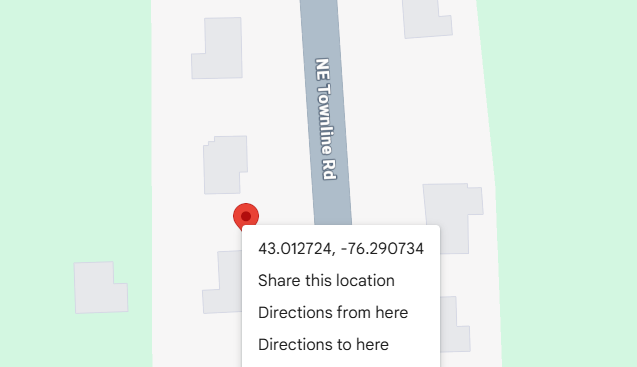

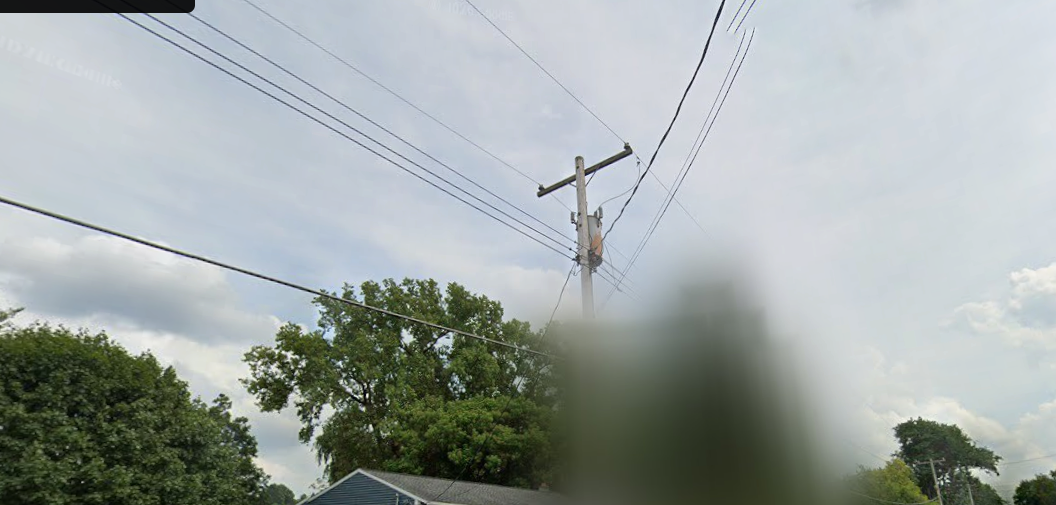

**Let's look at the transformer data to see all the nearest transformers to these coordinates:**

In [16]:
df_transformers = pd.read_parquet(r"C:\Users\u355394\OneDrive - IBERDROLA S.A\Documents - Asset Data Strategy\Asset Data Quality\SmartLink\data\cache\transformers\history\previous_transformer_snapshot.parquet")

**using balltree and one of the coordinates from the meter without candidates, let's see the nearest transformer**

We find a transformer within 550ft of those coordinates

In [17]:
from sklearn.neighbors import BallTree
import numpy as np

target = np.radians([[43.012694, -76.290707]])

transformer_coords = np.radians(
    df_transformers[["latitude", "longitude"]]
)

tree = BallTree(transformer_coords, metric="haversine")

dist, idx = tree.query(target, k=1)

nearest = df_transformers.iloc[idx[0][0]]

distance_ft = dist[0][0] * 6371000 * 3.28084

print(nearest["transformer_floc"])
print(nearest["latitude"])
print(nearest["longitude"])
print(f"{distance_ft:.1f} feet away")

9301-L0819-3433-0097-ED00014
43.01206505000005
-76.29028558999994
255.5 feet away


**After verification, this is because the transformer coordinates are identified as incorrect (outside of their assigned division**)

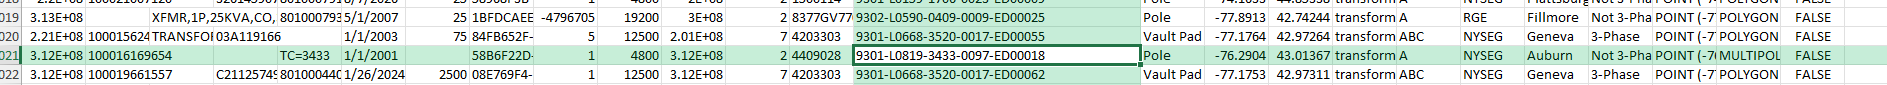

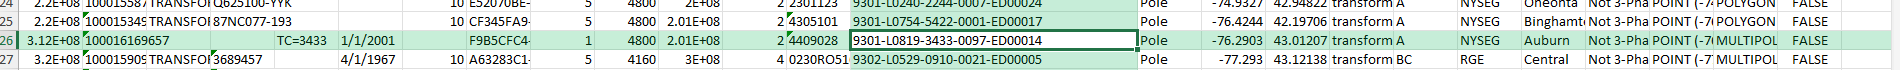

**COORDINATE VERIFICATION TEST PASSED**

**ARE ALL THE CORRECT CANDIDATE PAIRS REFLECTED IN CANDIDATE TILE AND FEATURE FILES??**

In [30]:
pairs_auburn = pairs_auburn[['meter_number', 'candidate_transformer']].drop_duplicates()
pairs_features = df_auburn_features[['meter_number', 'candidate_transformer']].drop_duplicates()
pairs_tile_features = df_auburn_tile_features[['meter_number', 'candidate_transformer']].drop_duplicates()

**CONCLUSION -> Candidates are all the same across dataframes**

In [32]:
pairs_a = set(map(tuple, pairs_auburn.to_numpy()))
pairs_b = set(map(tuple, pairs_features.to_numpy()))
pairs_c = set(map(tuple, pairs_tile_features.to_numpy()))

print("Auburn not in Features:", len(pairs_a - pairs_b))
print("Features not in Auburn:", len(pairs_b - pairs_a))

print("Auburn not in Tile Features:", len(pairs_a - pairs_c))
print("Tile Features not in Auburn:", len(pairs_c - pairs_a))

Auburn not in Features: 0
Features not in Auburn: 0
Auburn not in Tile Features: 0
Tile Features not in Auburn: 0


**Any above 550ft?**

In [22]:
final_merge = df_auburn_features.merge(df_auburn_tile_features, on=['meter_number', 'candidate_transformer'])

550 ft distance check -> Correct

In [23]:
from pathlib import Path
import pandas as pd

FINAL_DIR = Path(
    "data/cache/final_features/2026-10-16"
)

all_meters = []

for file in FINAL_DIR.glob("*.parquet"):

    df = pd.read_parquet(
        file,
        columns=["meter_number"],
    )

    all_meters.append(
        df["meter_number"]
    )

all_meters = pd.concat(
    all_meters,
    ignore_index=True,
)

print(
    f"Total meters: {len(all_meters):,}"
)

print(
    f"Total unique meters: "
    f"{all_meters.nunique():,}"
)

ValueError: No objects to concatenate

In [119]:
df_adam = pd.read_parquet(r"C:\Users\u355394\OneDrive - IBERDROLA S.A\Documents - Asset Data Strategy\Asset Data Quality\SmartLink\data\cache\adam\adam_validated.parquet")

**Historical Corrections**

In [25]:
df_historical = pd.read_parquet(r"C:\Users\u355394\OneDrive - IBERDROLA S.A\Documents - Asset Data Strategy\Asset Data Quality\SmartLink\data\cache\historical_corrections\2026-10-16\all_historical_corrections.parquet")

In [29]:
df_historical

,meter_number,historical_floc,final_recommended_floc,recommendation_sent,historical_conflict,division,latest_floc,historical_status,implementation_status,run_date
0,RSL0350000564,9302-L0539-0444-0308-PM00032,9302-L0539-0444-0045-ED00034,True,False,Central,9302-L0539-0444-0308-PM00032,ORIGINAL_ASSOCIATION,UNKNOWN,2026-10-16
1,RSL0350000656,9302-L0275-0450-0440-ED00072,9302-L0276-0450-0440-PM00100,True,False,Central,9302-L0275-0450-0440-ED00072,ORIGINAL_ASSOCIATION,UNKNOWN,2026-10-16
2,RSL0350000718,9302-L0327-0447-1030-PM00001,9302-L0327-0447-1030-PM00002,True,False,Central,9302-L0327-0447-1030-PM00001,ORIGINAL_ASSOCIATION,UNKNOWN,2026-10-16
3,RSL0350001115,9302-L0069-0466-1586-ED00014,9302-L0069-0466-1586-ED00017,True,False,Central,9302-L0069-0466-1586-ED00014,ORIGINAL_ASSOCIATION,UNKNOWN,2026-10-16
4,RSL0350001138,9302-L0886-0449-0390-PM00008,9302-L0886-0449-0390-PM00006,True,False,Central,9302-L0886-0449-0390-PM00008,ORIGINAL_ASSOCIATION,UNKNOWN,2026-10-16
...,...,...,...,...,...,...,...,...,...,...
78487,RSL0350111157,9302-L0282-0449-0559-PM00004,9302-L0282-0449-0559-PM00007,True,False,Central,9302-L0282-0449-0559-PM00007,MATCHES_PREVIOUS_RECOMMENDATION,UNKNOWN,2026-10-16
78488,RSL0350111176,9302-L0282-0449-0559-PM00004,9302-L0282-0449-0559-PM00007,True,False,Central,9302-L0282-0449-0559-PM00007,MATCHES_PREVIOUS_RECOMMENDATION,UNKNOWN,2026-10-16
78489,RSL0350111174,9302-L0282-0449-0559-PM00004,9302-L0282-0449-0559-PM00007,True,False,Central,9302-L0282-0449-0559-PM00007,MATCHES_PREVIOUS_RECOMMENDATION,UNKNOWN,2026-10-16
78490,RSL0350111143,9302-L0282-0449-0559-PM00004,9302-L0282-0449-0559-PM00007,True,False,Central,9302-L0282-0449-0559-PM00007,MATCHES_PREVIOUS_RECOMMENDATION,UNKNOWN,2026-10-16


In [27]:
df_historical.historical_status.value_counts()

historical_status
MATCHES_PREVIOUS_RECOMMENDATION    53430
ORIGINAL_ASSOCIATION               24132
DIFFERENT_ASSOCIATION                731
METER_NOT_IN_CURRENT_AMI             198
CURRENT_FLOC_MISSING                   1
Name: count, dtype: int64

In [28]:
df_historical[df_historical['historical_status'] == 'DIFFERENT_ASSOCIATION']

,meter_number,historical_floc,final_recommended_floc,recommendation_sent,historical_conflict,division,latest_floc,historical_status,implementation_status,run_date
521,RSL0350052800,9301-L0889-5115-0049-ED00058,9302-L0397-0461-0082-ED00150,True,False,Central,9302-L0397-0461-0200-ED00004,DIFFERENT_ASSOCIATION,UNKNOWN,2026-10-16
1920,RSL0350180692,9302-L0153-0470-0229-ED00216,9302-L0153-0470-0219-ED00152,True,False,Central,9302-L0256-0470-0229-ED00371,DIFFERENT_ASSOCIATION,UNKNOWN,2026-10-16
2186,RSL0350211614,9302-L0153-0471-0009-ED00002,9302-L0255-0470-0219-ED00034,True,False,Central,9302-L0256-0471-0070-ED00003,DIFFERENT_ASSOCIATION,UNKNOWN,2026-10-16
2187,RSL0350211615,9302-L0153-0471-0009-ED00002,9302-L0255-0470-0219-ED00034,True,False,Central,9302-L0256-0471-0070-ED00003,DIFFERENT_ASSOCIATION,UNKNOWN,2026-10-16
2641,RSL0350274046,9302-L0153-0471-0009-ED00002,9302-L0255-0470-0219-ED00034,True,False,Central,9302-L0256-0471-0070-ED00003,DIFFERENT_ASSOCIATION,UNKNOWN,2026-10-16
...,...,...,...,...,...,...,...,...,...,...
78242,RSL0350182279,9302-L0453-0573-0013-ED00007,9302-L0453-0573-0013-ED00003,True,False,Canandaigua,9302-L0915-0573-0003-ED00011,DIFFERENT_ASSOCIATION,UNKNOWN,2026-10-16
78263,RSL0350171047,9302-L0578-0585-0017-PM00009,9302-L0441-0585-0227-PM00011,True,False,Canandaigua,9302-L0578-0585-0017-PM00002,DIFFERENT_ASSOCIATION,UNKNOWN,2026-10-16
78427,RSL0350068186,9302-L0561-0449-0552-PM00001,9302-L0561-0449-0513-PM00019,True,False,Central,9302-L0561-0449-0550-PM00002,DIFFERENT_ASSOCIATION,UNKNOWN,2026-10-16
78428,RSL0350068187,9302-L0561-0449-0552-PM00001,9302-L0561-0449-0513-PM00019,True,False,Central,9302-L0561-0449-0550-PM00002,DIFFERENT_ASSOCIATION,UNKNOWN,2026-10-16
